In [3]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import jax
import jax.numpy as jnp
from jax.scipy.special import logsumexp

ImportError: DLL load failed while importing _profiler: An Application Control policy has blocked this file.

In [ ]:
# Lattice parameters
a1 = 5 + 0j  # Torus Lattice vector 1
a2 = 5j  # Torus Lattice vector 2
omega = a2 / a1  # Complex structure of the lattice
area = np.imag(a1 * np.conjugate(a2))  # Area of the unit cell
g1 = 2 * np.pi * 1j * a1 / area  # Reciprocal lattice vector 1
g2 = 2 * np.pi * -1j * a2 / area  # Reciprocal lattice vector 2
phi = 1 + 1j  # Magnetic flux through the unit cell
q_set = 3
N = 100
N_h = 2
N_phi = q_set*N + N_h
l_b = np.sqrt(np.imag(omega) / (N_phi * 2 * np.pi))
l = 5
s = 0
a = [0, 0, 0]

In [ ]:
_N_GRID = jnp.arange(-5, 5 + 1)
NpHALF = _N_GRID + 0.5
NpHALFsq = NpHALF**2
@jax.jit
def LogTheta(z, tau):
    z_shape = z.shape
    z_flat = z.reshape(-1)
    y = jnp.imag(z_flat)/jnp.imag(tau)
    x = jnp.real(z_flat-y*tau)
    n1 = jnp.floor(x)
    n2 = jnp.floor(y)
    z_flat_fund = (z_flat - n1 - n2*tau)

    log_theta_n = jnp.pi * 1j * NpHALFsq[:, None] * tau + 2*jnp.pi*1j*NpHALF[:, None]*(z_flat_fund[None, :]-0.5)
    log_qp = 1j*jnp.pi*(n1+n2) -jnp.pi*1j*tau*n2**2 - 2*jnp.pi*1j*n2*z_flat_fund
    total_exponent = log_theta_n + log_qp
    real_part = jnp.real(total_exponent)
    imag_part = jnp.imag(total_exponent)

    log_result = logsumexp(a=real_part, axis=0, b=jnp.exp(1j*imag_part))
    return log_result.reshape(z_shape)

In [ ]:
def log_f(z, a1, omega):
    w = np.asarray(z, dtype=complex) / a1
    return LogTheta(w, omega) + np.pi*(w**2 - np.abs(w)**2)/(2*omega.imag)

def K(z, s):
    return s*(np.cos(np.real(g1*np.conjugate(z)))+np.cos(np.real(g2*np.conjugate(z))))

def log_Psi(z, a, h):
    """
    Laughlin nu=1/q on the torus with quasiholes.
      z   : (N,) or (N, B)  electron coords (optional trailing batch axis)
      a   : (q,)            centre-of-mass zeros
      h   : (N_h,)          quasihole positions
      phi : scalar          flux / boundary-condition parameter
    Returns complex log Psi with shape () or (B,).
    """
    z = np.asarray(z, dtype=complex)
    a = np.asarray(a, dtype=complex)
    h = np.asarray(h, dtype=complex)
    q, N = len(a), z.shape[0]
    extra = (1,) * (z.ndim - 1)                     # broadcasting dims for the batch axis

    # Jastrow: sum over pairs i<j of q * log f(z_i - z_j)
    i, j = np.triu_indices(N, k=1)                  # all pairs i<j, no Python loop
    log_jas = q * log_f(z[i] - z[j], a1, omega).sum(axis=0)

    # Quasihole factors: sum over i, a of log f(z_i - h_a)
    dz = z[:, None] - h.reshape((1, -1) + extra)    # shape (N, N_h, ...)
    log_qh = log_f(dz, a1, omega).sum(axis=(0, 1))

    # Centre of mass, with the H/q correction
    Z = z.sum(axis=0) + h.sum() / q + phi / q       # sum over electrons only (axis=0)
    log_cm = log_f(Z[None] - a.reshape((-1,) + extra) if z.ndim > 1 else Z - a,
                   a1, omega).sum(axis=0)

    log_mod = -np.sum(K(z, s), axis=0)  # Modulation factor

    log_phase = np.pi*(np.conjugate(Z)*phi - np.conjugate(phi)*Z)/(2*np.imag(omega)*q)  # Phase factor

    return log_jas + log_qh + log_cm + log_mod + log_phase 

In [8]:
def mc_density(h, a, N, l, n_sweeps=4000, n_burn=400, bins=50):
    """Electron density rho(x, y) for quasiholes at h, from Metropolis sampling of |Psi(h)|^2.
    Coordinates live in [-l/2, l/2) x [-l/2, l/2) (square torus, side l)."""
    delta = 0.21
    z = np.random.uniform(-l/2, l/2, N) + 1j*np.random.uniform(-l/2, l/2, N)
    lp = log_Psi(z, a, h)
    positions = []
    pbar = tqdm(range(n_burn + n_sweeps), desc="burn-in")
    
    for sweep in pbar:
        for _ in range(N):                              # one sweep = N single-electron proposals
            idx = np.random.randint(N)
            z_new = z.copy()
            z_new[idx] += np.random.uniform(-delta, delta) + 1j*np.random.uniform(-delta, delta)
            lp_new = log_Psi(z_new, a, h)
            log_ratio = 2 * np.real(lp_new - lp)

            if log_ratio >= 0 or np.log(np.random.rand()) < log_ratio:
                z, lp = z_new, lp_new
        if sweep >= n_burn:
            # fold every electron back into the cell: |Psi| is periodic
            zw = ((z.real + l/2) % l - l/2) + 1j*((z.imag + l/2) % l - l/2)
            positions.append(zw.copy())

    pos = np.concatenate(positions)                     # all recorded electron positions
    H, xe, ye = np.histogram2d(pos.real, pos.imag, bins=bins,
                               range=[[-l/2, l/2], [-l/2, l/2]])
    bin_area = (xe[1] - xe[0]) * (ye[1] - ye[0])
    rho = H / (n_sweeps * bin_area)                     # per configuration per area: integrates to N
    return rho, xe, ye

In [12]:
def mc_overlap_shifting(h1, h2, a, N, l, mc_steps=40000, n_burn=7000):
    """Returns <Psi1|Psi2>/<Psi1|Psi1> = E_{|Psi1|^2}[Psi2/Psi1]. Its phase is what the Berry phase needs."""
    delta = 0.21
    z = np.random.uniform(-l/2, l/2, N) + 1j*np.random.uniform(-l/2, l/2, N)
    lp1 = log_Psi(z, a, h1)                 
    lp2 = log_Psi(z, a, h2)                 
    integral, n_meas, n_acc = 0.0 + 0j, 0, 0

    for i in range(n_burn + mc_steps):
        idx = np.random.randint(N)
        z_new = z.copy()
        z_new[idx] += np.random.uniform(-delta, delta) + 1j*np.random.uniform(-delta, delta)

        lp1_new = log_Psi(z_new, a, h1)
        if np.random.rand() < np.exp(2 * (lp1_new - lp1).real):   
            z, lp1 = z_new, lp1_new
            lp2 = log_Psi(z, a, h2)          
            n_acc += 1

        if i >= n_burn:
            integral += np.exp(lp2 - lp1)
            n_meas += 1

    print(f"acceptance = {n_acc/(n_burn+mc_steps):.2f}")   # aim for 0.3-0.6; tune delta
    return integral / n_meas

In [13]:
# Takes the stationary holes as inputs, addas a hole and takes around a radius r.

def braiding_phase(r, h, steps):
    phase = 0.0

    H = h.copy()
    H.append(0)
    H_ = H.copy()

    for k in tqdm(range(steps), desc="Computing braiding phase", unit="step"):
        theta = 2 * np.pi * k / steps

        H[-1] = r * np.exp(1j * theta)
        H_[-1] = r * np.exp(1j * (theta + 2 * np.pi / steps))

        overlap = mc_overlap_shifting(
            H, H_, a, N, l,
            mc_steps=40000,
            n_burn=8000
        )

        if abs(overlap) < 1e-12:
            raise ValueError(f"Overlap too small at step {k}: {overlap}")

        phase += np.angle(overlap)

    return phase

burn-in: 100%|██████████| 22000/22000 [30:28<00:00, 12.03it/s] 


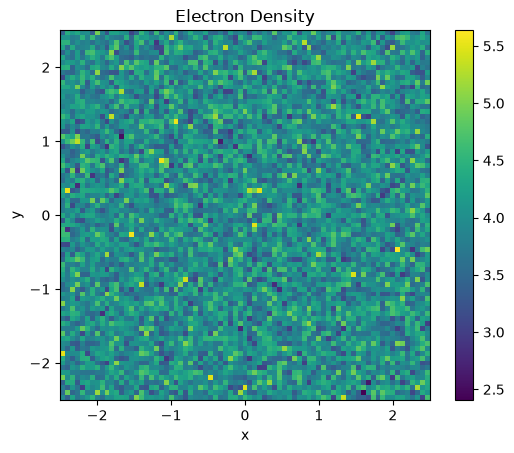

Integrated density: 100.00000000000001
Mean density: 3.9999999999999756
Expected mean: 4.0
Density standard deviation: 0.43057600954999536
Relative fluctuations: 0.1076440023874995


In [31]:
h_none = []
rho0, xe0, ye0 = mc_density(h_none, a, N, l, n_sweeps=20000, n_burn=2000, bins=75)
plt.imshow(rho0, extent=[-l/2, l/2, -l/2, l/2], origin='lower')
plt.colorbar()
plt.xlabel("x")
plt.ylabel("y")
plt.title("Electron Density")
plt.show()

bin_area = (xe0[1] - xe0[0]) * (ye0[1] - ye0[0])

print("Integrated density:", rho0.sum() * bin_area)
print("Mean density:", rho0.mean())
print("Expected mean:", N / l**2)
print("Density standard deviation:", rho0.std())
print("Relative fluctuations:", rho0.std() / rho0.mean())

burn-in: 100%|██████████| 48000/48000 [1:01:50<00:00, 12.94it/s]


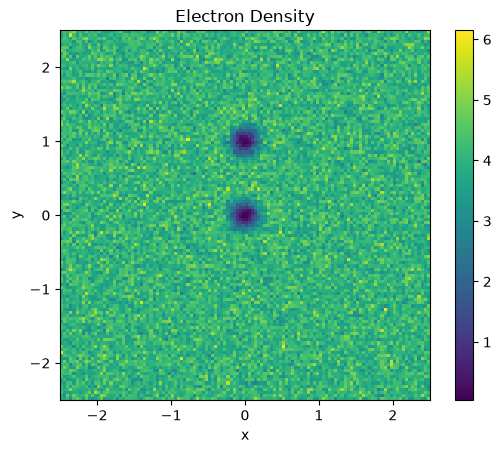

Integrated density: 100.0
Mean density: 4.000000000000028
Expected mean: 4.0
Density standard deviation: 0.5488636930969331
Relative fluctuations: 0.1372159232742323


In [48]:
h_1 = [0, 1]
rho1, xe1, ye1 = mc_density(h_1, a, N, l, n_sweeps=40000, n_burn=8000, bins=120)
plt.imshow(rho1, extent=[-l/2, l/2, -l/2, l/2], origin='lower')
plt.colorbar()
plt.xlabel("x")
plt.ylabel("y")
plt.title("Electron Density")
plt.show()

bin_area = (xe1[1] - xe1[0]) * (ye1[1] - ye1[0])

print("Integrated density:", rho1.sum() * bin_area)
print("Mean density:", rho1.mean())
print("Expected mean:", N / l**2)
print("Density standard deviation:", rho1.std())
print("Relative fluctuations:", rho1.std() / rho1.mean())

In [45]:
d_values = [0.3, 0.325, 0.35, 0.375, 0.4, 0.425]
phases_trial_none = []

for d in tqdm(d_values, desc="Scanning radius"):
    p = braiding_phase(d, h_none, steps = 60)
    phases_trial_none.append(p)

phases_trial = np.unwrap(phases_trial)

Scanning radius:   0%|          | 0/6 [00:00<?, ?it/s]

acceptance = 0.52


acceptance = 0.52


acceptance = 0.52


acceptance = 0.52


acceptance = 0.52


... (358 outputs left out)

acceptance = 0.52


Scanning radius: 100%|██████████| 6/6 [2:31:56<00:00, 1519.37s/it]

acceptance = 0.52


NameError: name 'phases_trial' is not defined

In [46]:
phases_trial_none = np.unwrap(phases_trial_none)

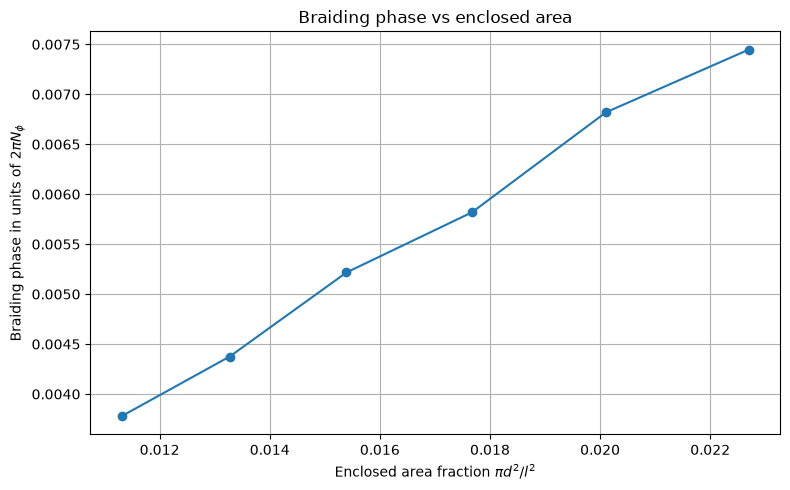

In [96]:
N_phi = q_set*N + 1

plt.figure(figsize=(8, 5))

plt.plot((np.pi * np.array(d_values)**2)/l**2, phases_trial_none / (2 * np.pi * N_phi), "o-")

plt.xlabel(r"Enclosed area fraction $\pi d^2/l^2$")
plt.ylabel(r"Braiding phase in units of $2\pi N_\phi$")
plt.title("Braiding phase vs enclosed area")
plt.grid(True)
plt.tight_layout()
plt.show()

In [83]:
print((np.pi * np.array(d_values)**2)/l**2, phases_trial_none / (2 * np.pi * N_phi))
print(np.pi * np.array(d_values), phases_trial_none)

[0.01130973 0.01327323 0.0153938  0.01767146 0.02010619 0.02269801] [0.00377861 0.00437573 0.00521683 0.00581836 0.0068195  0.00744672]
[0.9424778  1.02101761 1.09955743 1.17809725 1.25663706 1.33517688] [ 7.1462526  8.275547   9.86628   11.003912  12.897304  14.083518 ]


In [8]:
def linear_fit(data_x, data_y):
    data_x = np.asarray(data_x, dtype=float)
    data_y = np.asarray(data_y, dtype=float)
    n = len(data_x)
    if n != len(data_y):
        raise ValueError("data_x and data_y must have the same length")
    if n < 3:
        raise ValueError("Need at least 3 points to estimate errors (N-2 > 0)")

    x_mean = np.mean(data_x)
    y_mean = np.mean(data_y)

    num = 0.0
    denom = 0.0                              # this is S_xx
    for i in range(n):
        num += (data_x[i] - x_mean) * (data_y[i] - y_mean)
        denom += (data_x[i] - x_mean) ** 2
    if denom == 0:
        raise ValueError("All x values identical; slope undefined")

    m = num / denom
    c = y_mean - m * x_mean

    # --- Uncertainties ---
    resid_sq = 0.0
    for i in range(n):
        r = data_y[i] - (m * data_x[i] + c)  # residual of point i
        resid_sq += r ** 2
    s = np.sqrt(resid_sq / (n - 2))          # estimated noise std, N-2 dof

    dm = s / np.sqrt(denom)                  # error in slope
    dc = s * np.sqrt(1 / n + x_mean**2 / denom)  # error in intercept
    return m, c, dm, dc


In [103]:
print(linear_fit((np.pi * np.array(d_values)**2)/l**2, phases_trial_none / (2 * np.pi * N_phi)))

(np.float64(0.32920025166197714), np.float64(6.44645470806891e-05), np.float64(0.010651003612984466), np.float64(0.00018308147060928787))


In [104]:
q_set = 5
a = [0, 0, 0, 0, 0]

d_values = [0.3, 0.325, 0.35, 0.375, 0.4, 0.425]
phases_trial_none_5 = []

for d in tqdm(d_values, desc="Scanning radius"):
    p = braiding_phase(d, h_none, steps = 60)
    phases_trial_none_5.append(p)

phases_trial_none_5 = np.unwrap(phases_trial_none_5)

Scanning radius:   0%|          | 0/6 [00:00<?, ?it/s]

acceptance = 0.52


acceptance = 0.52


acceptance = 0.52


acceptance = 0.52


acceptance = 0.52


... (357 outputs left out)

acceptance = 0.52


acceptance = 0.52


Scanning radius: 100%|██████████| 6/6 [2:21:14<00:00, 1412.37s/it]

acceptance = 0.52


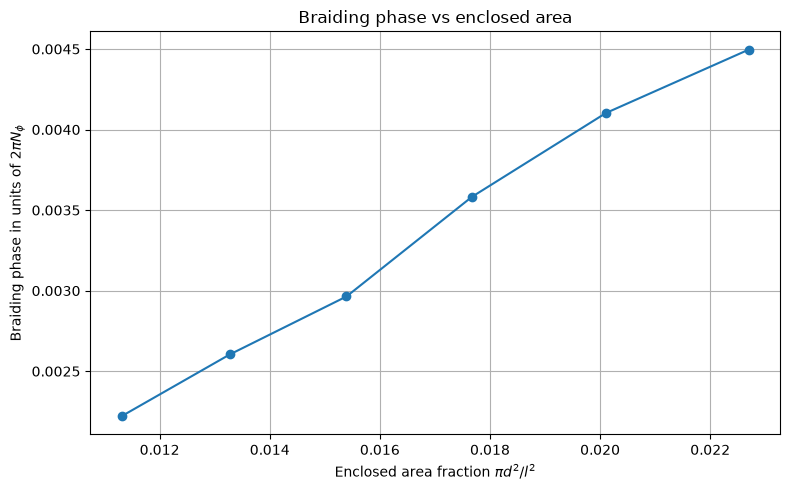

In [105]:
N_phi = q_set*N + 1

plt.figure(figsize=(8, 5))

plt.plot((np.pi * np.array(d_values)**2)/l**2, phases_trial_none_5 / (2 * np.pi * N_phi), "o-")

plt.xlabel(r"Enclosed area fraction $\pi d^2/l^2$")
plt.ylabel(r"Braiding phase in units of $2\pi N_\phi$")
plt.title("Braiding phase vs enclosed area")
plt.grid(True)
plt.tight_layout()
plt.show()

In [106]:
print((np.pi * np.array(d_values)**2)/l**2, phases_trial_none_5 / (2 * np.pi * N_phi))
print(np.pi * np.array(d_values), phases_trial_none_5)

[0.01130973 0.01327323 0.0153938  0.01767146 0.02010619 0.02269801] [0.00222098 0.00260393 0.00296397 0.00358228 0.00410284 0.00449606]
[0.9424778  1.02101761 1.09955743 1.17809725 1.25663706 1.33517688] [ 6.991371  8.196859  9.330219 11.276585 12.915231 14.153032]


In [107]:
print(linear_fit((np.pi * np.array(d_values)**2)/l**2, phases_trial_none_5 / (2 * np.pi * N_phi)))

(np.float64(0.20673510737943057), np.float64(-0.00013282891378590955), np.float64(0.007727379811383916), np.float64(0.00013282692516412275))


In [11]:
h_1 = [0]
a = [0, 0, 0]
q_set = 3

d_values = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75]
phases_trial_1_3 = []

for d in tqdm(d_values, desc="Scanning radius"):
    p = braiding_phase(d, h_1, steps = 80)
    phases_trial_1_3.append(p)

phases_trial_1_3 = np.unwrap(phases_trial_1_3)

Scanning radius:   0%|          | 0/6 [00:00<?, ?it/s]

acceptance = 0.52


acceptance = 0.52


acceptance = 0.51


acceptance = 0.52


acceptance = 0.52


... (477 outputs left out)

acceptance = 0.51


acceptance = 0.52


Scanning radius: 100%|██████████| 6/6 [3:09:01<00:00, 1890.19s/it]

acceptance = 0.52


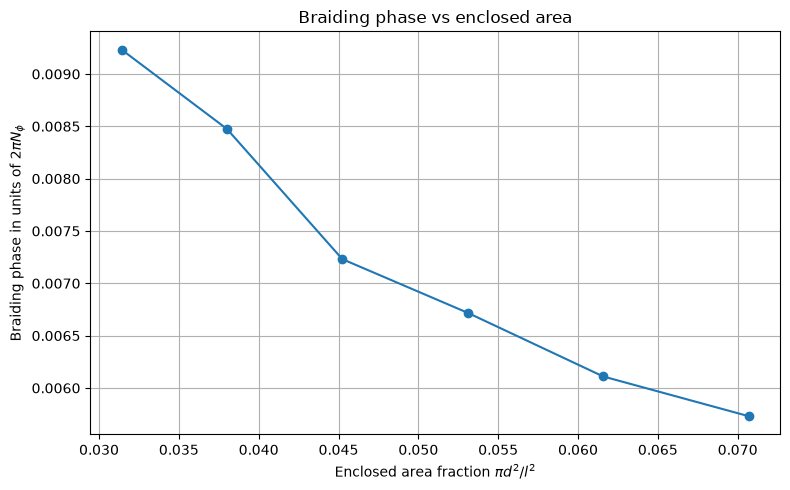

In [19]:
N_phi = q_set*N + 2

plt.figure(figsize=(8, 5))

plt.plot((np.pi * np.array(d_values)**2)/l**2, phases_trial_1_3 / (2 * np.pi * N_phi), "o-")

plt.xlabel(r"Enclosed area fraction $\pi d^2/l^2$")
plt.ylabel(r"Braiding phase in units of $2\pi N_\phi$")
plt.title("Braiding phase vs enclosed area")
plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
print((np.pi * np.array(d_values)**2)/l**2, phases_trial_1_3 / (2 * np.pi * N_phi))
print(np.pi * np.array(d_values), phases_trial_1_3)

[0.03141593 0.03801327 0.04523893 0.05309292 0.06157522 0.07068583] [0.00923242 0.00847462 0.00723083 0.00671817 0.00611014 0.00573068]
[1.57079633 1.72787596 1.88495559 2.04203522 2.19911486 2.35619449] [17.518719 16.080784 13.720665 12.747877 11.59412  10.874084]


In [21]:
print(linear_fit((np.pi * np.array(d_values)**2)/l**2, phases_trial_1_3 / (2 * np.pi * N_phi)))

(np.float64(-0.09019515307182484), np.float64(0.01175956654715864), np.float64(0.010835986731426587), np.float64(0.0005610590040434403))


In [38]:
h_1 = [0]
a = [0, 0, 0]
q_set = 3

d_values = [1.5, 1.55, 1.6, 1.65, 1.7]
phases_trial_1_3_2 = []

for d in tqdm(d_values, desc="Scanning radius"):
    p = braiding_phase(d, h_1, steps = 120)
    phases_trial_1_3_2.append(p)

phases_trial_1_3_2 = np.unwrap(phases_trial_1_3_2)

Scanning radius:   0%|          | 0/5 [00:00<?, ?it/s]

acceptance = 0.52


acceptance = 0.52


acceptance = 0.52


acceptance = 0.51


acceptance = 0.52


... (596 outputs left out)

acceptance = 0.52


acceptance = 0.52


Scanning radius: 100%|██████████| 5/5 [8:50:37<00:00, 6367.46s/it]  

acceptance = 0.52


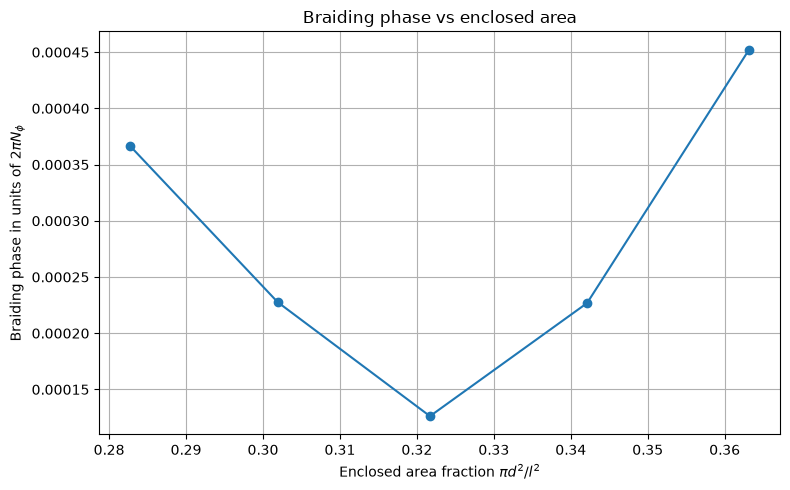

In [53]:
N_phi = q_set*N + 2

plt.figure(figsize=(8, 5))

plt.plot((np.pi * np.array(d_values)**2)/l**2, (phases_trial_1_3_2 % (2 * np.pi)) / (2 * np.pi * N_phi), "o-")

plt.xlabel(r"Enclosed area fraction $\pi d^2/l^2$")
plt.ylabel(r"Braiding phase in units of $2\pi N_\phi$")
plt.title("Braiding phase vs enclosed area")
plt.grid(True)
plt.tight_layout()
plt.show()

In [43]:
print((np.pi * np.array(d_values)**2)/l**2, phases_trial_1_3_2 / (2 * np.pi * N_phi))
print(np.pi * np.array(d_values), phases_trial_1_3_2)

[0.28274334 0.30190705 0.32169909 0.34211944 0.36316811] [0.09308168 0.09294286 0.09284143 0.09294204 0.09316748]
[4.71238898 4.86946861 5.02654825 5.18362788 5.34070751] [176.62454 176.36113 176.16866 176.35957 176.78734]


In [45]:
print(linear_fit((np.pi * np.array(d_values)**2)/l**2, phases_trial_1_3_2 / (2 * np.pi * N_phi)))

(np.float64(0.000921327074307131), np.float64(0.0926981307571621), np.float64(0.0022776222305209326), np.float64(0.0007369920678861946))


In [16]:

def mc_overlap_shifting_data(
    h1, h2, a, N, l, b_size= 50,
    mc_blocks= 600, n_burn=3000
):
    """Estimate <Psi1|Psi2>/<Psi1|Psi1> using Metropolis sampling.

    Returns:
        result: Complex overlap estimate.
        error_real: Standard error of its real part.
        error_imag: Standard error of its imaginary part.
        mc_data: Post-update configurations from production.
    """
    delta = 0.21

    z = (
        np.random.uniform(-l/2, l/2, N)
        + 1j * np.random.uniform(-l/2, l/2, N)
    )

    lp1 = log_Psi(z, a, h1)
    lp2 = log_Psi(z, a, h2)

    n_acc = 0
    mc_data = []
    block_means = []

    # Burn-in: do not record configurations.
    for i in range(n_burn):
        idx = np.random.randint(N)
        z_new = z.copy()

        z_new[idx] += (
            np.random.uniform(-delta, delta)
            + 1j * np.random.uniform(-delta, delta)
        )

        lp1_new = log_Psi(z_new, a, h1)

        if np.random.rand() < np.exp(
            2 * (lp1_new - lp1).real
        ):
            z, lp1 = z_new, lp1_new
            lp2 = log_Psi(z, a, h2)
            n_acc += 1

    # Production: one measurement per attempted particle move.
    for i in range(mc_blocks):
        block_values = []

        for j in range(b_size):
            idx = np.random.randint(N)
            z_new = z.copy()

            z_new[idx] += (
                np.random.uniform(-delta, delta)
                + 1j * np.random.uniform(-delta, delta)
            )

            lp1_new = log_Psi(z_new, a, h1)

            if np.random.rand() < np.exp(
                2 * (lp1_new - lp1).real
            ):
                z, lp1 = z_new, lp1_new
                lp2 = log_Psi(z, a, h2)
                n_acc += 1

            # Record the current state, after accept/reject.
            mc_data.append(z.copy())

            # Complex overlap estimator.
            block_values.append(np.exp(lp2 - lp1))

        block_means.append(np.mean(block_values))

    block_means = np.asarray(block_means)

    result = np.mean(block_means)

    error_real = np.sqrt(
        np.var(block_means.real, ddof=1) / mc_blocks
    )
    error_imag = np.sqrt(
        np.var(block_means.imag, ddof=1) / mc_blocks
    )

    acceptance = n_acc / (n_burn + mc_blocks * b_size)

    print(f"Acceptance = {acceptance:.3f}")
    print(f"Overlap = {result}")
    print(f"SE(real) = {error_real:.4g}")
    print(f"SE(imag) = {error_imag:.4g}")

    return result, error_real, error_imag, mc_data


In [17]:

# Adds a hole and braids it in a circular loop in the presence of stationary holes

def braiding_phase_data(r, h, steps):
    phase = 0.0
    phase_variance = 0.0
    phase_errors = []

    H = h.copy()
    H.append(0j)
    H_ = H.copy()

    data = []
    errors = []
    overlaps = []

    for k in tqdm(
        range(steps),
        desc="Computing braiding phase",
        unit="step"
    ):
        theta = 2 * np.pi * k / steps

        H[-1] = r * np.exp(1j * theta)
        H_[-1] = r * np.exp(
            1j * (theta + 2 * np.pi / steps)
        )

        overlap = mc_overlap_shifting_data(
            H, H_, a, N, l,
            b_size=20,
            mc_blocks=2000,
            n_burn=8000
        )

        value = overlap[0]
        sigma_x = overlap[1]
        sigma_y = overlap[2]
        configurations = overlap[3]

        if abs(value) < 1e-12:
            raise ValueError(
                f"Overlap too small at step {k}: {value}"
            )

        overlaps.append(value)
        errors.append([sigma_x, sigma_y])
        data.append(configurations)

        # Phase contribution from this overlap
        phi = np.angle(value)
        phase += phi

        # First-order propagation of real/imaginary errors
        x = value.real
        y = value.imag
        modulus_squared = abs(value)**2

        sigma_phi_squared = (
            y**2 * sigma_x**2
            + x**2 * sigma_y**2
        ) / modulus_squared**2

        sigma_phi = np.sqrt(sigma_phi_squared)

        phase_errors.append(sigma_phi)
        phase_variance += sigma_phi_squared

    accumulated_error = np.sqrt(phase_variance)
    phase_wrapped = np.angle(np.exp(1j * phase))

    return (
        phase_wrapped,
        accumulated_error,
        phase_errors,
        data,
        errors,
        overlaps
    )




In [15]:
h = [2j]
a = [0, 0, 0]
q_set = 3
l = 5

d_values = [0.3, 0.325, 0.35, 0.375, 0.4]
phases_2holes_nobraiding = []
phases_2holes_nobraiding_errors = []
phase_2holes_nobraiding_error_data = []
position_2holes_nobraiding_data = []
error_2holes_nobraiding_data = []
overlaps_2holes_nobraiding_data = []

for d in tqdm(d_values, desc="Scanning radius"):
    p = braiding_phase_data(d, h, steps = 60)
    phases_2holes_nobraiding.append(p[0])
    phases_2holes_nobraiding_errors.append(p[1])
    phase_2holes_nobraiding_error_data.append(p[2])
    position_2holes_nobraiding_data.append(p[3])
    error_2holes_nobraiding_data.append(p[4])
    overlaps_2holes_nobraiding_data.append(p[5])

phases_2holes_nobraiding = np.unwrap(phases_2holes_nobraiding)
error = np.asarray(phases_2holes_nobraiding_errors)


Scanning radius:   0%|          | 0/5 [00:00<?, ?it/s]

Acceptance = 0.520
Overlap = (0.9780029058456421+0.12389951944351196j)
SE(real) = 0.00191
SE(imag) = 0.001882


Acceptance = 0.518
Overlap = (0.9915984869003296+0.11491075158119202j)
SE(real) = 0.001602
SE(imag) = 0.001763


Acceptance = 0.522
Overlap = (0.9963061809539795+0.09841331839561462j)
SE(real) = 0.002154
SE(imag) = 0.001806


Acceptance = 0.518
Overlap = (0.9803287386894226+0.10204164683818817j)
SE(real) = 0.001746
SE(imag) = 0.001579


Acceptance = 0.521
Overlap = (0.9813524484634399+0.10564529895782471j)
SE(real) = 0.001631
SE(imag) = 0.001467


... (297 outputs left out)

Acceptance = 0.518
Overlap = (0.9592674374580383+0.17478257417678833j)
SE(real) = 0.002384
SE(imag) = 0.002238


Acceptance = 0.514
Overlap = (0.9808647036552429+0.21210920810699463j)
SE(real) = 0.002263
SE(imag) = 0.002087


Scanning radius: 100%|██████████| 5/5 [21:17:31<00:00, 15330.39s/it]  

Acceptance = 0.515
Overlap = (0.9882109761238098+0.17890030145645142j)
SE(real) = 0.002189
SE(imag) = 0.002183


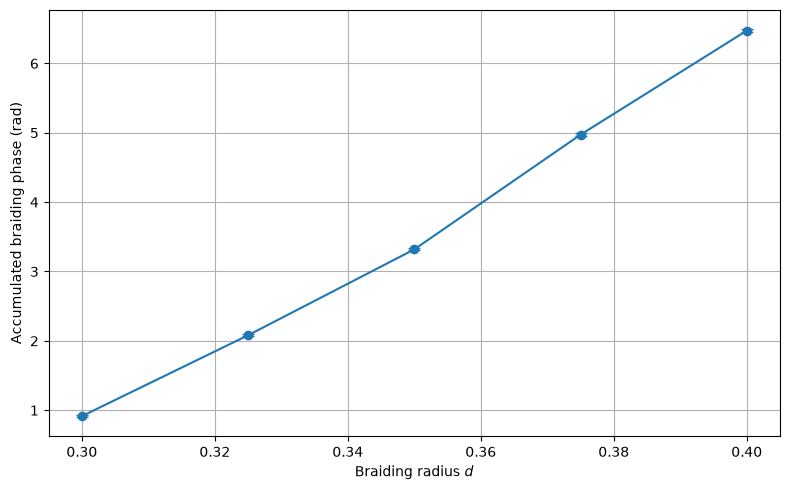

In [16]:

phases = np.asarray(phases_2holes_nobraiding)
errors = np.asarray(phases_2holes_nobraiding_errors)

plt.figure(figsize=(8, 5))
plt.errorbar(d_values, phases, yerr=errors, fmt="o-", capsize=4)
plt.xlabel("Braiding radius $d$")
plt.ylabel("Accumulated braiding phase (rad)")
plt.grid(True)
plt.tight_layout()
plt.show()

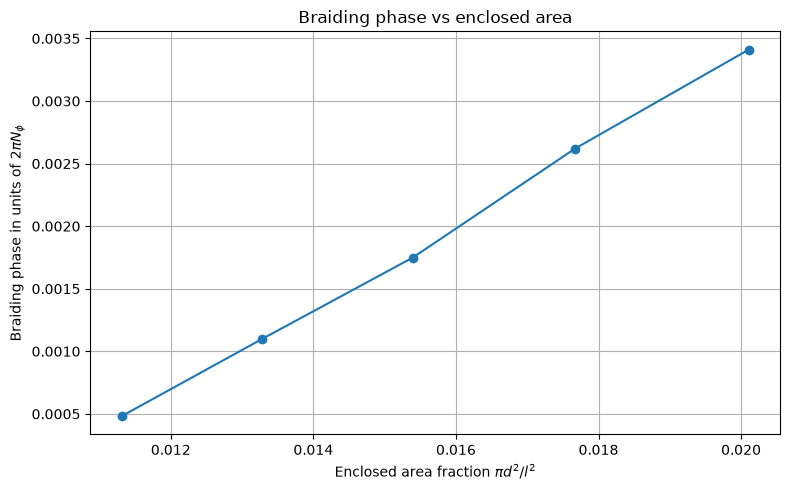

In [17]:
N_phi = q_set*N + 2

plt.figure(figsize=(8, 5))

plt.plot((np.pi * np.array(d_values)**2)/l**2, phases_2holes_nobraiding / (2 * np.pi * N_phi), "o-")

plt.xlabel(r"Enclosed area fraction $\pi d^2/l^2$")
plt.ylabel(r"Braiding phase in units of $2\pi N_\phi$")
plt.title("Braiding phase vs enclosed area")
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
print(linear_fit((np.pi * np.array(d_values)**2)/l**2, phases_2holes_nobraiding / (2 * np.pi * N_phi)))

(np.float64(0.33598796517736895), np.float64(-0.003353231312450757), np.float64(0.00722426984662425), np.float64(0.00011457233412244357))


In [1]:
np.savez(
    "braiding_results_q3_none.npz",
    d_values=np.array(d_values),
    phases_2holes_nobraiding=np.array(phases_2holes_nobraiding),
    phases_2holes_nobraiding_errors=np.array(phases_2holes_nobraiding_errors),
    phase_error_data=np.array(phase_2holes_nobraiding_error_data, dtype=object),
    position_data=np.array(position_2holes_nobraiding_data, dtype=object),
    error_data=np.array(error_2holes_nobraiding_data, dtype=object),
    overlaps_data=np.array(overlaps_2holes_nobraiding_data, dtype=object)
)

NameError: name 'np' is not defined

In [7]:
print(-0.003353231312450757*2*np.pi*302 / (2*np.pi))

-1.0126758563601286


In [18]:
h = [0]
a = [0, 0, 0]
q_set = 3
l = 5

d_values = [1.0, 1.025, 1.05, 1.075, 1.1]
phases_2holes_braiding = []
phases_2holes_braiding_errors = []
phase_2holes_braiding_error_data = []
position_2holes_braiding_data = []
error_2holes_braiding_data = []
overlaps_2holes_braiding_data = []

for d in tqdm(d_values, desc="Scanning radius"):
    p = braiding_phase_data(d, h, steps = 80)
    phases_2holes_braiding.append(p[0])
    phases_2holes_braiding_errors.append(p[1])
    phase_2holes_braiding_error_data.append(p[2])
    position_2holes_braiding_data.append(p[3])
    error_2holes_braiding_data.append(p[4])
    overlaps_2holes_braiding_data.append(p[5])

phases_2holes_braiding = np.unwrap(phases_2holes_braiding)
error = np.asarray(phases_2holes_braiding_errors)

Scanning radius:   0%|          | 0/5 [00:00<?, ?it/s]

Acceptance = 0.516
Overlap = (0.5569679141044617+0.740695595741272j)
SE(real) = 0.004261
SE(imag) = 0.004386


Acceptance = 0.518
Overlap = (0.5969486236572266+0.7802520990371704j)
SE(real) = 0.003783
SE(imag) = 0.003393


Acceptance = 0.518
Overlap = (0.5619771480560303+0.7827657461166382j)
SE(real) = 0.00455
SE(imag) = 0.004646


Acceptance = 0.517
Overlap = (0.6069263219833374+0.7888587117195129j)
SE(real) = 0.003963
SE(imag) = 0.004116


Acceptance = 0.526
Overlap = (0.5712717175483704+0.7797001600265503j)
SE(real) = 0.004286
SE(imag) = 0.004575


... (397 outputs left out)

Acceptance = 0.515
Overlap = (0.43847620487213135+0.9052172303199768j)
SE(real) = 0.005143
SE(imag) = 0.005097


Acceptance = 0.522
Overlap = (0.3799251914024353+0.8605924248695374j)
SE(real) = 0.004453
SE(imag) = 0.00401


Scanning radius: 100%|██████████| 5/5 [7:44:56<00:00, 5579.29s/it]  

Acceptance = 0.519
Overlap = (0.3686871826648712+0.8755277991294861j)
SE(real) = 0.004818
SE(imag) = 0.004566


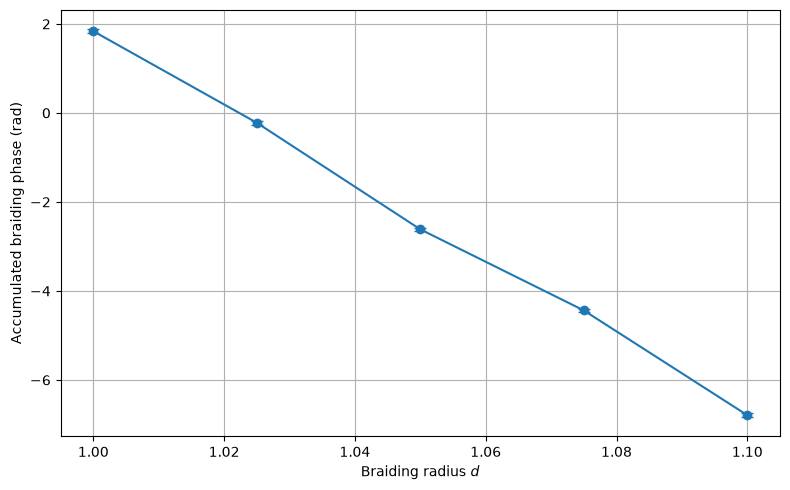

In [20]:
phases = np.asarray(phases_2holes_braiding)
errors = np.asarray(phases_2holes_braiding_errors)

plt.figure(figsize=(8, 5))
plt.errorbar(d_values, phases, yerr=errors, fmt="o-", capsize=4)
plt.xlabel("Braiding radius $d$")
plt.ylabel("Accumulated braiding phase (rad)")
plt.grid(True)
plt.tight_layout()
plt.show()

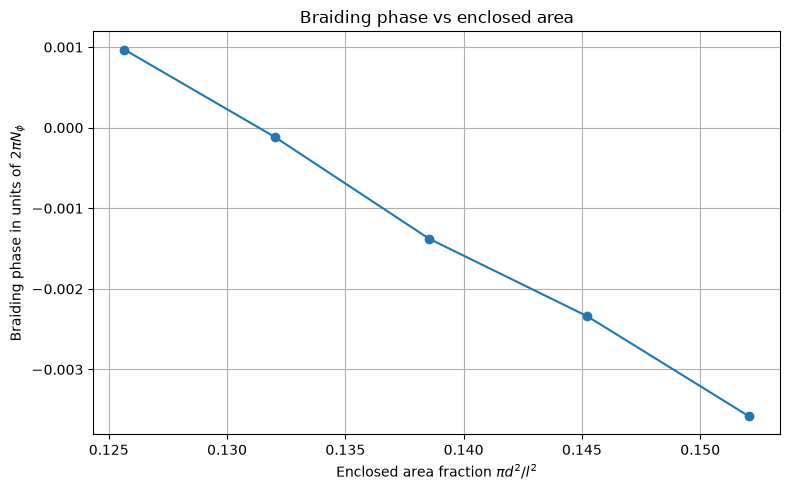

In [21]:
N_phi = q_set*N + 2

plt.figure(figsize=(8, 5))

plt.plot((np.pi * np.array(d_values)**2)/l**2, phases_2holes_braiding / (2 * np.pi * N_phi), "o-")

plt.xlabel(r"Enclosed area fraction $\pi d^2/l^2$")
plt.ylabel(r"Braiding phase in units of $2\pi N_\phi$")
plt.title("Braiding phase vs enclosed area")
plt.grid(True)
plt.tight_layout()
plt.show()

In [23]:
print(linear_fit((np.pi * np.array(d_values)**2)/l**2, phases_2holes_braiding / (2 * np.pi * N_phi)))

(np.float64(-0.17150929444894214), np.float64(0.022499429985816898), np.float64(0.0038565036362544487), np.float64(0.0005361111861168367))


In [1]:

import numpy as np
from tqdm.auto import tqdm


def mc_overlap_shifting_data(
    h1, h2, a, N, l,
    b_size=20,
    mc_blocks=2000,
    n_burn=8000
):
    """
    Estimate <Psi1|Psi2>/<Psi1|Psi1> using Metropolis sampling.

    Returns:
        result: Complex overlap estimate.
        error_real: Standard error of its real part.
        error_imag: Standard error of its imaginary part.
        cov_xy: Estimated covariance of the real and imaginary
                parts of the overlap estimator.
        acceptance: Overall Metropolis acceptance ratio.
    """

    delta = 0.21

    # Initial configuration
    z = (
        np.random.uniform(-l/2, l/2, N)
        + 1j * np.random.uniform(-l/2, l/2, N)
    )

    lp1 = log_Psi(z, a, h1)
    lp2 = log_Psi(z, a, h2)

    n_acc = 0
    block_means = []

    # -------------------------
    # Burn-in
    # -------------------------

    for i in range(n_burn):

        idx = np.random.randint(N)
        z_new = z.copy()

        z_new[idx] += (
            np.random.uniform(-delta, delta)
            + 1j * np.random.uniform(-delta, delta)
        )

        lp1_new = log_Psi(z_new, a, h1)

        if np.random.rand() < np.exp(
            2 * (lp1_new - lp1).real
        ):
            z = z_new
            lp1 = lp1_new
            lp2 = log_Psi(z, a, h2)

            n_acc += 1

    # -------------------------
    # Production
    # -------------------------

    for i in range(mc_blocks):

        block_values = []

        for j in range(b_size):

            idx = np.random.randint(N)
            z_new = z.copy()

            z_new[idx] += (
                np.random.uniform(-delta, delta)
                + 1j * np.random.uniform(-delta, delta)
            )

            lp1_new = log_Psi(z_new, a, h1)

            if np.random.rand() < np.exp(
                2 * (lp1_new - lp1).real
            ):
                z = z_new
                lp1 = lp1_new
                lp2 = log_Psi(z, a, h2)

                n_acc += 1

            # Complex overlap estimator
            block_values.append(np.exp(lp2 - lp1))

        block_means.append(np.mean(block_values))

    # -------------------------
    # Blocking statistics
    # -------------------------

    block_means = np.asarray(block_means)

    result = np.mean(block_means)

    error_real = (
        np.std(block_means.real, ddof=1)
        / np.sqrt(mc_blocks)
    )

    error_imag = (
        np.std(block_means.imag, ddof=1)
        / np.sqrt(mc_blocks)
    )

    # Covariance of the estimated overlap components
    cov_xy = (
        np.cov(
            block_means.real,
            block_means.imag,
            ddof=1
        )[0, 1] / mc_blocks
    )

    acceptance = n_acc / (n_burn + mc_blocks * b_size)

    print(f"Acceptance = {acceptance:.3f}")
    print(f"Overlap = {result}")
    print(f"SE(real) = {error_real:.4g}")
    print(f"SE(imag) = {error_imag:.4g}")

    return (
        result,
        error_real,
        error_imag,
        cov_xy,
        acceptance
    )

In [20]:

def braiding_phase_data(r, h, steps):

    phase = 0.0
    phase_variance = 0.0

    phase_errors = []
    errors = []
    overlaps = []

    H = h.copy()
    H.append(0j)

    H_ = H.copy()

    for k in tqdm(
        range(steps),
        desc="Computing braiding phase",
        unit="step"
    ):

        theta = 2 * np.pi * k / steps

        # Initial and final quasihole configurations
        H[-1] = r * np.exp(1j * theta)

        H_[-1] = r * np.exp(
            1j * (theta + 2 * np.pi / steps)
        )

        overlap = mc_overlap_shifting_data(
            H, H_, a, N, l,
            b_size=180,
            mc_blocks=180,
            n_burn=6000
        )

        value = overlap[0]
        sigma_x = overlap[1]
        sigma_y = overlap[2]
        cov_xy = overlap[3]

        if abs(value) < 1e-12:
            raise ValueError(
                f"Overlap too small at step {k}: {value}"
            )

        overlaps.append(value)
        errors.append([sigma_x, sigma_y])

        # -------------------------
        # Phase accumulation
        # -------------------------

        phi = np.angle(value)
        phase += phi

        # -------------------------
        # Phase uncertainty
        # -------------------------

        x = value.real
        y = value.imag

        modulus_squared = abs(value)**2

        sigma_phi_squared = (
            y**2 * sigma_x**2
            + x**2 * sigma_y**2
            - 2 * x * y * cov_xy
        ) / modulus_squared**2

        # Protect against tiny negative values from roundoff
        sigma_phi_squared = max(
            sigma_phi_squared, 0.0
        )

        sigma_phi = np.sqrt(sigma_phi_squared)

        phase_errors.append(sigma_phi)
        phase_variance += sigma_phi_squared

    # -------------------------
    # Final phase and uncertainty
    # -------------------------

    accumulated_error = np.sqrt(phase_variance)

    phase_wrapped = np.angle(
        np.exp(1j * phase)
    )

    return (
        phase_wrapped,
        accumulated_error,
        phase_errors,
        errors,
        overlaps
    )


In [12]:

h = [0]

a = [0, 0, 0]
q_set = 3
l = 5
N_phi = q_set*N + 2

d_values = [0.825, 0.85, 0.875, 0.9, 0.925]

phases_2holes_braiding_trial2 = []
phases_2holes_braiding_errors_trial2 = []

phase_error_data_trial2 = []
overlaps_data_trial2 = []

for d in tqdm(d_values, desc="Scanning radius"):

    p = braiding_phase_data(
        d,
        h,
        steps=180
    )

    phases_2holes_braiding_trial2.append(p[0])

    phases_2holes_braiding_errors_trial2.append(p[1])

    phase_error_data_trial2.append(p[2])

    overlaps_data_trial2.append(p[4])


# Unwrap the phases across different radii
phases_2holes_braiding = np.unwrap(
    phases_2holes_braiding_trial2
)

error = np.asarray(
    phases_2holes_braiding_errors_trial2
)


Scanning radius:   0%|          | 0/5 [00:00<?, ?it/s]

Acceptance = 0.522
Overlap = (0.9608898758888245+0.2573525905609131j)
SE(real) = 0.00443
SE(imag) = 0.003725


Acceptance = 0.521
Overlap = (0.9607855081558228+0.27636468410491943j)
SE(real) = 0.004854
SE(imag) = 0.00546


Acceptance = 0.517
Overlap = (0.9686338901519775+0.2642596662044525j)
SE(real) = 0.004612
SE(imag) = 0.003724


Acceptance = 0.515
Overlap = (0.9446180462837219+0.2798420786857605j)
SE(real) = 0.004204
SE(imag) = 0.005023


Acceptance = 0.518
Overlap = (0.9602394700050354+0.2524123787879944j)
SE(real) = 0.004517
SE(imag) = 0.003654


... (896 outputs left out)

Acceptance = 0.518
Overlap = (0.9242975115776062+0.35871419310569763j)
SE(real) = 0.004822
SE(imag) = 0.005173


Acceptance = 0.522
Overlap = (0.9449090361595154+0.3467310965061188j)
SE(real) = 0.005278
SE(imag) = 0.005102


Scanning radius: 100%|██████████| 5/5 [13:33:33<00:00, 9762.71s/it]  

Acceptance = 0.516
Overlap = (0.9321255683898926+0.3466072380542755j)
SE(real) = 0.007658
SE(imag) = 0.005135


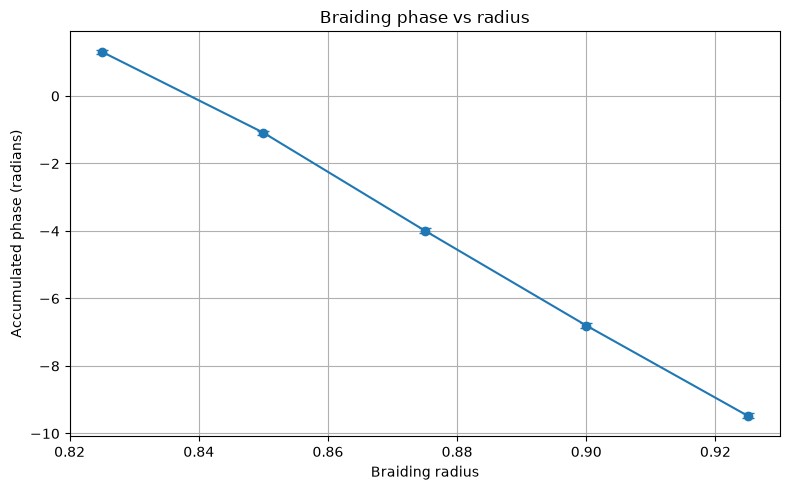

In [13]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.errorbar(
    d_values,
    phases_2holes_braiding,
    yerr=error,
    fmt="o-",
    capsize=4
)

plt.xlabel("Braiding radius")
plt.ylabel("Accumulated phase (radians)")
plt.title("Braiding phase vs radius")

plt.grid(True)
plt.tight_layout()
plt.show()


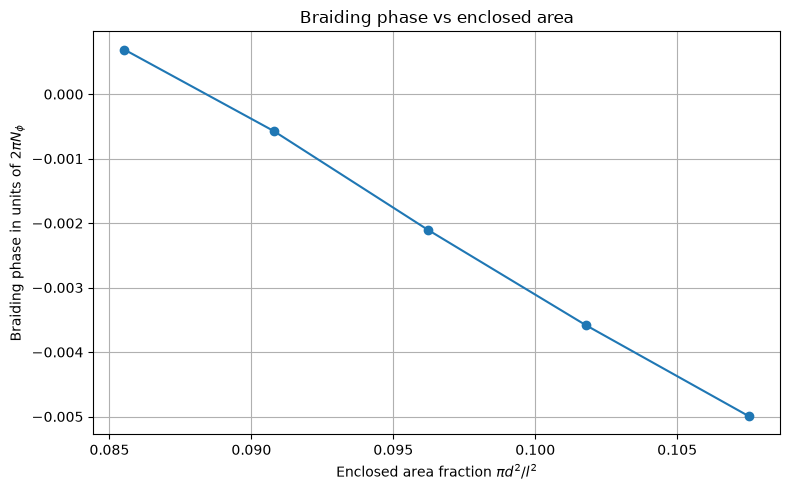

In [14]:
plt.figure(figsize=(8, 5))

plt.plot((np.pi * np.array(d_values)**2)/l**2, phases_2holes_braiding / (2 * np.pi * N_phi), "o-")

plt.xlabel(r"Enclosed area fraction $\pi d^2/l^2$")
plt.ylabel(r"Braiding phase in units of $2\pi N_\phi$")
plt.title("Braiding phase vs enclosed area")
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
print(linear_fit((np.pi * np.array(d_values)**2)/l**2, phases_2holes_braiding / (2 * np.pi * N_phi)))

(np.float64(-0.2615535053790808), np.float64(0.023092748906703278), np.float64(0.0037503215439468503), np.float64(0.000362587021399435))


In [24]:

h = [0]
h_none = []

a = [0, 0, 0]
q_set = 3
l = 5
N_phi = q_set*N + 2

d_values = [1.2, 1.225, 1.25]

phases_2holes_braiding_trial3 = []
phases_2holes_braiding_errors_trial3 = []

phase_error_data_trial3 = []
overlaps_data_trial3 = []

for d in tqdm(d_values, desc="Scanning radius"):

    p = braiding_phase_data(
        d,
        h,
        steps=420
    )

    phases_2holes_braiding_trial3.append(p[0])

    phases_2holes_braiding_errors_trial3.append(p[1])

    phase_error_data_trial3.append(p[2])

    overlaps_data_trial3.append(p[4])


# Unwrap the phases across different radii
phases_2holes_braiding_2 = np.unwrap(
    phases_2holes_braiding_trial3
)

error_2 = np.asarray(
    phases_2holes_braiding_errors_trial3
)

Scanning radius:   0%|          | 0/3 [00:00<?, ?it/s]

Acceptance = 0.519
Overlap = (0.9714693427085876+0.26600849628448486j)
SE(real) = 0.003604
SE(imag) = 0.002662


Acceptance = 0.516
Overlap = (0.9654815793037415+0.25061485171318054j)
SE(real) = 0.002834
SE(imag) = 0.003744


Acceptance = 0.518
Overlap = (0.9663519859313965+0.25912976264953613j)
SE(real) = 0.002547
SE(imag) = 0.002902


Acceptance = 0.518
Overlap = (0.9633773565292358+0.25680965185165405j)
SE(real) = 0.003474
SE(imag) = 0.003238


Acceptance = 0.517
Overlap = (0.9663365483283997+0.26542937755584717j)
SE(real) = 0.003133
SE(imag) = 0.002998


... (15 outputs left out)

Acceptance = 0.514
Overlap = (0.9648188352584839+0.24979285895824432j)
SE(real) = 0.003124
SE(imag) = 0.002892


Acceptance = 0.517
Overlap = (0.9527153968811035+0.24509456753730774j)
SE(real) = 0.003086
SE(imag) = 0.002507


Scanning radius:   0%|          | 0/3 [17:06<?, ?it/s]


KeyboardInterrupt: 

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.errorbar(
    d_values,
    phases_2holes_braiding_2,
    yerr=error_2,
    fmt="o-",
    capsize=4
)

plt.xlabel("Braiding radius")
plt.ylabel("Accumulated phase (radians)")
plt.title("Braiding phase vs radius")

plt.grid(True)
plt.tight_layout()
plt.show()

NameError: name 'phases_2holes_braiding_2' is not defined

<Figure size 800x500 with 0 Axes>

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot((np.pi * np.array(d_values)**2)/l**2, phases_2holes_braiding_2 / (2 * np.pi * N_phi), "o-")

plt.xlabel(r"Enclosed area fraction $\pi d^2/l^2$")
plt.ylabel(r"Braiding phase in units of $2\pi N_\phi$")
plt.title("Braiding phase vs enclosed area")
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
import numpy as np
from tqdm.auto import tqdm


def loop_berry_phase(r, static_holes, steps, center=0j,
                     mc_kwargs=None, max_step_phase=1.0):
    """
    Unwrapped Berry phase for moving ONE quasihole around a closed circle
    of radius r about `center`, with the other quasiholes fixed.

    Discretised Berry phase (Pancharatnam / Wilson loop):
        gamma = sum_k arg <Psi(w_k) | Psi(w_{k+1})>
    (Sign convention: the physical Berry phase i∮<ψ|∂ψ> = -sum arg(...);
     keep whichever sign you use consistent for both loops.)

    Returns
    -------
    gamma : float      unwrapped total phase (NOT reduced mod 2π)
    sigma : float      propagated statistical error
    step_phases : list per-step phases (for diagnostics)
    """
    if mc_kwargs is None:
        mc_kwargs = dict(b_size=180, mc_blocks=180, n_burn=6000)

    static_holes = list(static_holes)
    gamma = 0.0
    variance = 0.0
    step_phases = []

    for k in tqdm(range(steps), desc=f"loop r={r:.3f}", leave=False):

        # Positions of the moving hole at the start and end of this step
        w0 = center + r * np.exp(2j * np.pi * k / steps)
        w1 = center + r * np.exp(2j * np.pi * (k + 1) / steps)

        # Full quasihole lists: static holes + moving hole (moving one last)
        H0 = static_holes + [w0]
        H1 = static_holes + [w1]

        # MC estimate of <Psi(H0)|Psi(H1)> / <Psi(H0)|Psi(H0)>
        value, sx, sy, cxy, _ = mc_overlap_shifting_data(
            H0, H1, a, N, l, **mc_kwargs
        )

        if abs(value) < 1e-12:
            raise ValueError(f"Overlap vanished at step {k}: {value}")

        # Per-step phase. np.angle is in (-π, π]; this is unambiguous
        # ONLY if the true per-step phase is well below π. Check it.
        phi = np.angle(value)
        if abs(phi) > max_step_phase:
            print(f"Warning: step {k} phase = {phi:.3f} rad; "
                  f"increase `steps` to avoid branch ambiguity.")
        step_phases.append(phi)

        # Accumulate WITHOUT wrapping; this is the unwrapped Berry phase
        gamma += phi

        # Error propagation for phi = atan2(y, x):
        # σ_φ² = (y²σx² + x²σy² - 2xy cov) / |z|⁴
        x, y = value.real, value.imag
        mod2 = x * x + y * y
        s2 = (y**2 * sx**2 + x**2 * sy**2 - 2 * x * y * cxy) / mod2**2
        variance += max(s2, 0.0)

    return gamma, np.sqrt(variance), step_phases


def wrap(phi):
    """Reduce an angle to (-π, π]."""
    return np.angle(np.exp(1j * phi))

In [30]:
steps = 180
d_values = [0.825, 0.85, 0.875, 0.9, 0.925]

# Static hole INSIDE the loop (at the loop centre)
h_in = [0j]

# Static hole far OUTSIDE the loop. On a torus of side l centred at 0,
# the corner (l/2, l/2) is the farthest point from the origin
# (distance l/√2 ≈ 3.5 here vs loop radius ≤ 0.93).
# If your geometry is NOT periodic, pick a point well inside the bulk
# but several ℓ_B outside the loop instead.
h_out = [l/2 + 1j * l/2]

results = []

for d in tqdm(d_values, desc="Scanning radius"):

    # Loop enclosing the static hole: AB + braiding  (180 overlaps)
    g_in,  e_in,  sp_in  = loop_berry_phase(d, h_in,  steps)

    # Same loop, static hole outside: AB only        (180 overlaps)
    g_out, e_out, sp_out = loop_berry_phase(d, h_out, steps)

    # Difference cancels AB; what remains is the braiding phase
    braid = g_in - g_out
    braid_err = np.sqrt(e_in**2 + e_out**2)   # independent MC runs

    results.append(dict(
        d=d,
        gamma_in=g_in, gamma_out=g_out,
        err_in=e_in, err_out=e_out,
        braid=braid, braid_wrapped=wrap(braid),
        braid_err=braid_err,
        steps_in=sp_in, steps_out=sp_out,
    ))

    print(f"d={d:.3f}: braid = {wrap(braid):+.4f} ± {braid_err:.4f} rad  "
          f"(expect ±2π/3 = ±{2*np.pi/3:.4f})")

braid_over_2pi = np.array([r['braid_wrapped'] for r in results]) / (2*np.pi)

Scanning radius:   0%|          | 0/5 [00:00<?, ?it/s]

loop r=0.825:   0%|          | 0/180 [00:00<?, ?it/s]

Acceptance = 0.520
Overlap = (0.9641978144645691+0.2867019474506378j)
SE(real) = 0.006004
SE(imag) = 0.005817
Acceptance = 0.517
Overlap = (0.9488292336463928+0.2686921954154968j)
SE(real) = 0.005913
SE(imag) = 0.005062
Acceptance = 0.520
Overlap = (0.9682540893554688+0.2739895284175873j)
SE(real) = 0.004294
SE(imag) = 0.004702
Acceptance = 0.520
Overlap = (0.9613122940063477+0.2918764650821686j)
SE(real) = 0.005224
SE(imag) = 0.004942
Acceptance = 0.518
Overlap = (0.9465064406394958+0.27784407138824463j)
SE(real) = 0.005144
SE(imag) = 0.004815
Acceptance = 0.521
Overlap = (0.942175567150116+0.2714717984199524j)
SE(real) = 0.004359
SE(imag) = 0.004336
Acceptance = 0.518
Overlap = (0.9421719908714294+0.2649391293525696j)
SE(real) = 0.00453
SE(imag) = 0.004186
Acceptance = 0.520
Overlap = (0.9671883583068848+0.2769016623497009j)
SE(real) = 0.003415
SE(imag) = 0.004677
Acceptance = 0.517
Overlap = (0.9589031934738159+0.27931487560272217j)
SE(real) = 0.004422
SE(imag) = 0.004564
Acceptance

loop r=0.825:   0%|          | 0/180 [00:00<?, ?it/s]

Acceptance = 0.521
Overlap = (0.9387146234512329+0.3109784424304962j)
SE(real) = 0.004319
SE(imag) = 0.004758
Acceptance = 0.516
Overlap = (0.9390122890472412+0.2838057279586792j)
SE(real) = 0.004401
SE(imag) = 0.00429
Acceptance = 0.514
Overlap = (0.946276843547821+0.2746641933917999j)
SE(real) = 0.00508
SE(imag) = 0.004331
Acceptance = 0.518
Overlap = (0.9516786932945251+0.29294002056121826j)
SE(real) = 0.003949
SE(imag) = 0.00433
Acceptance = 0.515
Overlap = (0.947955846786499+0.27863821387290955j)
SE(real) = 0.003208
SE(imag) = 0.004409
Acceptance = 0.516
Overlap = (0.941781759262085+0.2940528690814972j)
SE(real) = 0.004567
SE(imag) = 0.005001
Acceptance = 0.521
Overlap = (0.9434190392494202+0.2808090150356293j)
SE(real) = 0.004626
SE(imag) = 0.004259
Acceptance = 0.521
Overlap = (0.9272061586380005+0.29205936193466187j)
SE(real) = 0.004731
SE(imag) = 0.0057
Acceptance = 0.516
Overlap = (0.9529587626457214+0.3023154139518738j)
SE(real) = 0.004199
SE(imag) = 0.005295
Acceptance = 0.

loop r=0.850:   0%|          | 0/180 [00:00<?, ?it/s]

... (11 outputs left out)

loop r=0.925:   0%|          | 0/180 [00:00<?, ?it/s]

Acceptance = 0.518
Overlap = (0.9311081171035767+0.3487494885921478j)
SE(real) = 0.005313
SE(imag) = 0.005046
Acceptance = 0.518
Overlap = (0.9282897710800171+0.32386377453804016j)
SE(real) = 0.004512
SE(imag) = 0.005636
Acceptance = 0.516
Overlap = (0.937089204788208+0.34026917815208435j)
SE(real) = 0.005617
SE(imag) = 0.004573
Acceptance = 0.515
Overlap = (0.9161235094070435+0.34021690487861633j)
SE(real) = 0.007802
SE(imag) = 0.00587
Acceptance = 0.521
Overlap = (0.925060510635376+0.3711117208003998j)
SE(real) = 0.006091
SE(imag) = 0.005967
Acceptance = 0.518
Overlap = (0.9400631189346313+0.351711630821228j)
SE(real) = 0.004775
SE(imag) = 0.005573
Acceptance = 0.516
Overlap = (0.9394193291664124+0.3540958762168884j)
SE(real) = 0.004974
SE(imag) = 0.004872
Acceptance = 0.521
Overlap = (0.9344173073768616+0.3372489809989929j)
SE(real) = 0.005847
SE(imag) = 0.005975
Acceptance = 0.522
Overlap = (0.9136086106300354+0.33432286977767944j)
SE(real) = 0.004981
SE(imag) = 0.005153
Acceptance

loop r=0.925:   0%|          | 0/180 [00:00<?, ?it/s]

Acceptance = 0.518
Overlap = (0.9101341962814331+0.3793647289276123j)
SE(real) = 0.005724
SE(imag) = 0.00587
Acceptance = 0.516
Overlap = (0.9154735803604126+0.3353567123413086j)
SE(real) = 0.005144
SE(imag) = 0.004577
Acceptance = 0.513
Overlap = (0.9304741621017456+0.3503030836582184j)
SE(real) = 0.007376
SE(imag) = 0.005574
Acceptance = 0.521
Overlap = (0.9389413595199585+0.3599150776863098j)
SE(real) = 0.004027
SE(imag) = 0.004779
Acceptance = 0.520
Overlap = (0.9255475997924805+0.3473261594772339j)
SE(real) = 0.005136
SE(imag) = 0.004645
Acceptance = 0.517
Overlap = (0.9349196553230286+0.35382866859436035j)
SE(real) = 0.004737
SE(imag) = 0.004159
Acceptance = 0.516
Overlap = (0.9428291320800781+0.36492636799812317j)
SE(real) = 0.005387
SE(imag) = 0.004995
Acceptance = 0.519
Overlap = (0.9364959597587585+0.3584490418434143j)
SE(real) = 0.005183
SE(imag) = 0.00446
Acceptance = 0.516
Overlap = (0.9434346556663513+0.3590017557144165j)
SE(real) = 0.004855
SE(imag) = 0.00482
Acceptance 

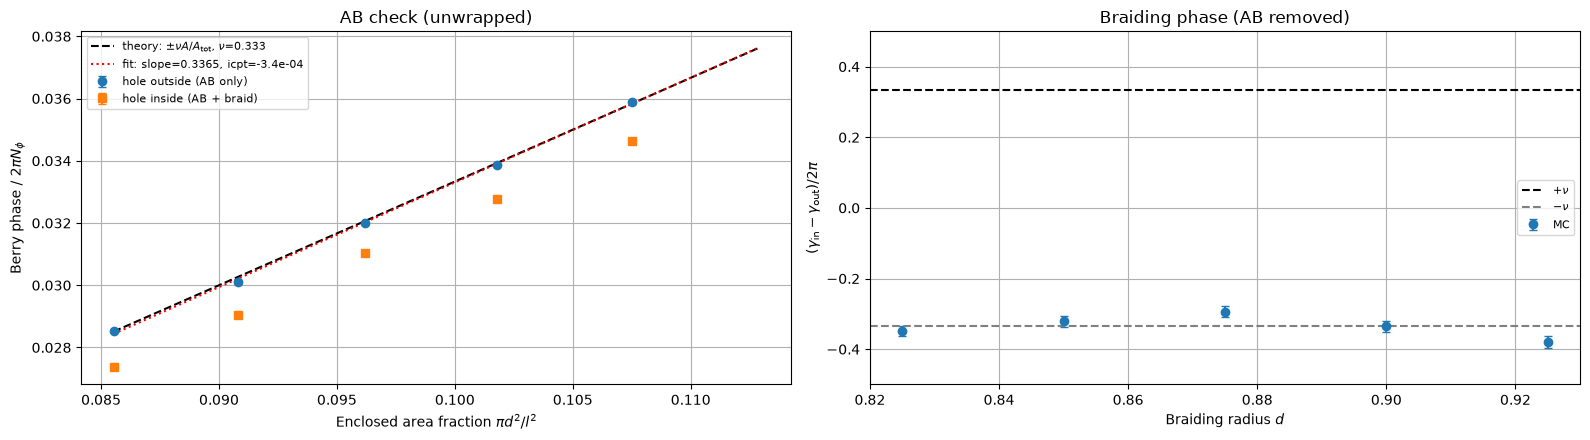

AB fit slope = 0.3365  (expect ±0.3333),  intercept = -3.40e-04
d=0.825:  braid/2π = -0.3495 ± 0.0145
d=0.850:  braid/2π = -0.3214 ± 0.0150
d=0.875:  braid/2π = -0.2936 ± 0.0152
d=0.900:  braid/2π = -0.3354 ± 0.0161
d=0.925:  braid/2π = -0.3802 ± 0.0164


In [35]:
import matplotlib.pyplot as plt

nu = 1 / q_set

# ---------- Unpack results into arrays ----------
d_arr     = np.array([r['d']         for r in results])
g_in      = np.array([r['gamma_in']  for r in results])
g_out     = np.array([r['gamma_out'] for r in results])
e_in      = np.array([r['err_in']    for r in results])
e_out     = np.array([r['err_out']   for r in results])
braid     = np.array([r['braid']     for r in results])
braid_err = np.array([r['braid_err'] for r in results])

# Enclosed area as a fraction of the total area (A_tot = l² for an l×l cell)
area_frac = np.pi * d_arr**2 / l**2

# Normalise phases by 2π N_φ, so the AB term is just ν·(area fraction)
norm = 2 * np.pi * N_phi

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

# =====================================================================
# Plot 1: AB check. Unwrapped phase vs enclosed area.
#   Expect gamma_out/(2πN_φ) = ±ν · A/A_tot  (straight line through 0)
#   gamma_in should be the same line shifted by the braiding phase
# =====================================================================
ax = axes[0]
ax.errorbar(area_frac, g_out / norm, yerr=e_out / norm,
            fmt='o', capsize=3, label='hole outside (AB only)')
ax.errorbar(area_frac, g_in / norm, yerr=e_in / norm,
            fmt='s', capsize=3, label='hole inside (AB + braid)')

# Weighted linear fit to gamma_out: slope should be ±ν, intercept ≈ 0
slope, icpt = np.polyfit(area_frac, g_out / norm, 1, w=norm / e_out)

# Theory line, with the sign taken from the data (sign convention dependent)
x_th = np.linspace(area_frac.min(), area_frac.max() * 1.05, 50)
ax.plot(x_th, np.sign(slope) * nu * x_th, 'k--',
        label=fr'theory: $\pm\nu A/A_{{\rm tot}}$, $\nu$={nu:.3f}')
ax.plot(x_th, slope * x_th + icpt, 'r:',
        label=f'fit: slope={slope:.4f}, icpt={icpt:.1e}')

ax.set_xlabel(r'Enclosed area fraction $\pi d^2/l^2$')
ax.set_ylabel(r'Berry phase / $2\pi N_\phi$')
ax.set_title('AB check (unwrapped)')
ax.legend(fontsize=8)
ax.grid(True)

# =====================================================================
# Plot 2: Braiding phase vs radius.
#   Expect braid/2π = ±1/3 mod 1, independent of d
# =====================================================================
ax = axes[1]
# Wrap braid/2π into (-1/2, 1/2] so ±1/3 both sit away from the cut
b_over_2pi = wrap(braid) / (2 * np.pi)

ax.errorbar(d_arr, b_over_2pi, yerr=braid_err / (2 * np.pi),
            fmt='o', capsize=3, label='MC')
ax.axhline(+nu, color='k', ls='--', label=r'$+\nu$')
ax.axhline(-nu, color='gray', ls='--', label=r'$-\nu$')

ax.set_xlabel('Braiding radius $d$')
ax.set_ylabel(r'$(\gamma_{\rm in}-\gamma_{\rm out})/2\pi$')
ax.set_title('Braiding phase (AB removed)')
ax.set_ylim(-0.5, 0.5)
ax.legend(fontsize=8)
ax.grid(True)


plt.tight_layout()
plt.show()

# ---------- Numbers ----------
print(f"AB fit slope = {slope:.4f}  (expect ±{nu:.4f}),  intercept = {icpt:.2e}")
for r, b in zip(results, b_over_2pi):
    print(f"d={r['d']:.3f}:  braid/2π = {b:+.4f} ± {r['braid_err']/(2*np.pi):.4f}")